<a href="https://colab.research.google.com/github/20canpolat09-gif/league-of-legends-match-predictor/blob/main/FashionMNIST_CNN_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Final Project: Fashion-MNIST Classification

Create Fashion-MNIST dataset objects, display the first three validation images using `show_data`, and train a CNN targeting at least 85% validation accuracy. Run all cells in order in Google Colab with internet access, then save the executed notebook.

## 1. Imports and setup

In [1]:
import random, numpy as np, matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| Device:", device)

PyTorch: 2.14.1+cu130 | Device: cuda


## 2. Create dataset objects
Fashion-MNIST contains grayscale 28×28 images across 10 clothing classes.

In [2]:
transform=transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])
full_train_dataset=datasets.FashionMNIST("./data", train=True, download=True, transform=transform)
test_dataset=datasets.FashionMNIST("./data", train=False, download=True, transform=transform)
train_dataset, validation_dataset=random_split(
    full_train_dataset, [54000,6000],
    generator=torch.Generator().manual_seed(SEED))
class_names=["T-shirt/top","Trouser","Pullover","Dress","Coat",
             "Sandal","Shirt","Sneaker","Bag","Ankle boot"]
BATCH_SIZE=128
train_loader=DataLoader(train_dataset,batch_size=BATCH_SIZE,shuffle=True)
validation_loader=DataLoader(validation_dataset,batch_size=BATCH_SIZE,shuffle=False)
test_loader=DataLoader(test_dataset,batch_size=BATCH_SIZE,shuffle=False)
print("Training:",len(train_dataset),"Validation:",len(validation_dataset),"Test:",len(test_dataset))
print("Image shape:",full_train_dataset[0][0].shape)

100%|██████████| 26.4M/26.4M [00:02<00:00, 12.8MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 203kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.77MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 22.5MB/s]

Training: 54000 Validation: 6000 Test: 10000
Image shape: torch.Size([1, 28, 28])


## 3. First three validation images (`show_data`)
Capture a screenshot of this output for the first assessment upload.

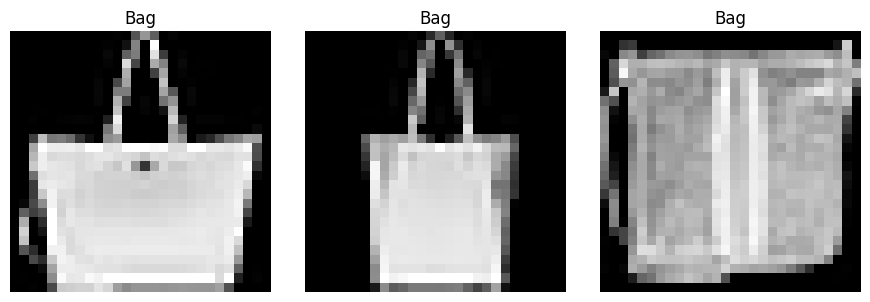

In [3]:
def show_data(dataset, number_of_images=3):
    number_of_images=min(number_of_images,len(dataset))
    fig,axes=plt.subplots(1,number_of_images,figsize=(3*number_of_images,3))
    if number_of_images==1: axes=[axes]
    for i,ax in enumerate(axes):
        image,label=dataset[i]
        image=image.squeeze().numpy()*0.5+0.5
        ax.imshow(image,cmap="gray")
        ax.set_title(class_names[label])
        ax.axis("off")
    plt.tight_layout()
    plt.show()

show_data(validation_dataset,3)

## 4. Define CNN
Two convolutional blocks learn image features; batch normalization and dropout support stable training and generalization.

In [4]:
class FashionCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features=nn.Sequential(
            nn.Conv2d(1,32,3,padding=1), nn.BatchNorm2d(32), nn.ReLU(inplace=True),
            nn.Conv2d(32,32,3,padding=1), nn.ReLU(inplace=True),
            nn.MaxPool2d(2), nn.Dropout2d(0.10),
            nn.Conv2d(32,64,3,padding=1), nn.BatchNorm2d(64), nn.ReLU(inplace=True),
            nn.Conv2d(64,64,3,padding=1), nn.ReLU(inplace=True),
            nn.MaxPool2d(2), nn.Dropout2d(0.15))
        self.classifier=nn.Sequential(
            nn.Flatten(), nn.Linear(64*7*7,256), nn.ReLU(inplace=True),
            nn.Dropout(0.30), nn.Linear(256,10))
    def forward(self,x):
        return self.classifier(self.features(x))
model=FashionCNN().to(device)
print(model)

FashionCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU(inplace=True)
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Dropout2d(p=0.1, inplace=False)
    (7): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (9): ReLU(inplace=True)
    (10): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (13): Dropout2d(p=0.15, inplace=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_fea

## 5. Loss and optimizer
Cross-entropy is used for multi-class classification. SGD uses the requested learning rate of 0.1.

In [5]:
criterion=nn.CrossEntropyLoss()
optimizer=optim.SGD(model.parameters(),lr=0.1,momentum=0.9,weight_decay=1e-4)
scheduler=optim.lr_scheduler.StepLR(optimizer,step_size=6,gamma=0.3)
EPOCHS=20
print(criterion)
print(optimizer)

CrossEntropyLoss()
SGD (
Parameter Group 0
    dampening: 0
    differentiable: False
    foreach: None
    fused: None
    initial_lr: 0.1
    lr: 0.1
    maximize: False
    momentum: 0.9
    nesterov: False
    weight_decay: 0.0001
)


## 6. Train and validate
The best validation checkpoint is retained. The target is at least 85%; actual accuracy is measured and printed.

In [7]:
def evaluate(model,loader):
    model.eval()
    total_loss=0.0; correct=0; total=0
    with torch.no_grad():
        for x,y in loader:
            x,y=x.to(device),y.to(device)
            logits=model(x)
            loss=criterion(logits,y)
            total_loss += loss.item()*x.size(0)
            correct += (logits.argmax(1)==y).sum().item()
            total += y.size(0)
    return total_loss/total,correct/total

history={"train_cost":[],"validation_cost":[],"validation_accuracy":[]}
best_accuracy=0.0
best_state=None
for epoch in range(EPOCHS):
    model.train()
    total_cost=0.0; seen=0
    for x,y in train_loader:
        x,y=x.to(device),y.to(device)
        optimizer.zero_grad()
        loss=criterion(model(x),y)
        loss.backward()
        optimizer.step()
        total_cost += loss.item()*x.size(0)
        seen += y.size(0)
    train_cost=total_cost/seen
    val_cost,val_acc=evaluate(model,validation_loader)
    history["train_cost"].append(train_cost)
    history["validation_cost"].append(val_cost)
    history["validation_accuracy"].append(val_acc)
    if val_acc>best_accuracy:
        best_accuracy=val_acc
        best_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
    scheduler.step()
    print(f"Epoch {epoch+1}/{EPOCHS} | Train cost {train_cost:.4f} | Val cost {val_cost:.4f} | Val accuracy {val_acc:.2%}")
if best_state is not None: model.load_state_dict(best_state)
print(f"Best validation accuracy: {best_accuracy:.2%}")
print("85% target achieved." if best_accuracy>=0.85 else "85% target not reached; try GPU or more epochs.")

Epoch 1/20 | Train cost 0.2467 | Val cost 0.2339 | Val accuracy 91.25%
Epoch 2/20 | Train cost 0.2345 | Val cost 0.2280 | Val accuracy 91.30%
Epoch 3/20 | Train cost 0.2210 | Val cost 0.2122 | Val accuracy 92.03%
Epoch 4/20 | Train cost 0.1733 | Val cost 0.1905 | Val accuracy 93.10%
Epoch 5/20 | Train cost 0.1602 | Val cost 0.1884 | Val accuracy 92.95%
Epoch 6/20 | Train cost 0.1535 | Val cost 0.1912 | Val accuracy 93.38%
Epoch 7/20 | Train cost 0.1471 | Val cost 0.1902 | Val accuracy 93.12%
Epoch 8/20 | Train cost 0.1400 | Val cost 0.1916 | Val accuracy 93.15%
Epoch 9/20 | Train cost 0.1367 | Val cost 0.1891 | Val accuracy 93.05%
Epoch 10/20 | Train cost 0.1204 | Val cost 0.1796 | Val accuracy 93.52%
Epoch 11/20 | Train cost 0.1155 | Val cost 0.1827 | Val accuracy 93.45%
Epoch 12/20 | Train cost 0.1105 | Val cost 0.1832 | Val accuracy 93.33%
Epoch 13/20 | Train cost 0.1087 | Val cost 0.1884 | Val accuracy 93.47%
Epoch 14/20 | Train cost 0.1061 | Val cost 0.1809 | Val accuracy 93.57%
E

## 7. Plot cost and validation accuracy
Capture a screenshot of these plots for the second assessment upload.

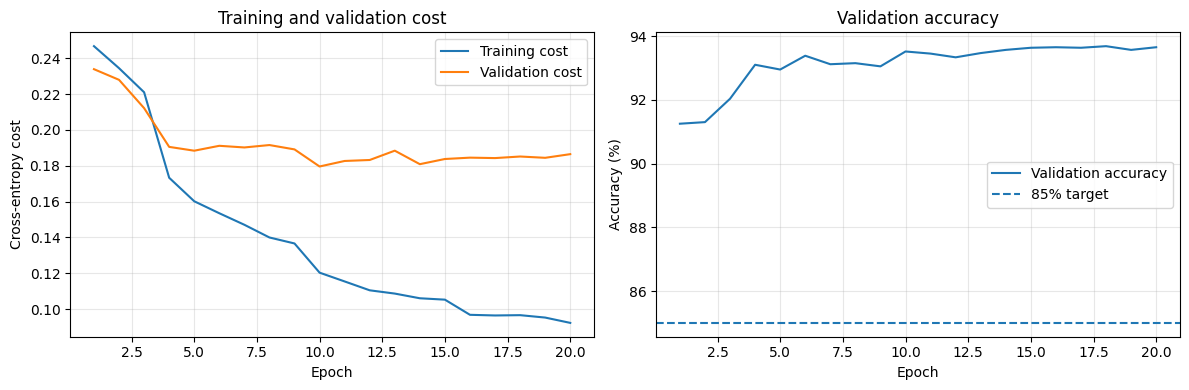

In [10]:
epochs=range(1,len(history["train_cost"])+1)
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].plot(epochs,history["train_cost"],label="Training cost")
axes[0].plot(epochs,history["validation_cost"],label="Validation cost")
axes[0].set(xlabel="Epoch",ylabel="Cross-entropy cost",title="Training and validation cost")
axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].plot(epochs,[a*100 for a in history["validation_accuracy"]],label="Validation accuracy")
axes[1].axhline(85,linestyle="--",label="85% target")
axes[1].set(xlabel="Epoch",ylabel="Accuracy (%)",title="Validation accuracy")
axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 8. Test-set evaluation

In [8]:
test_loss,test_accuracy=evaluate(model,test_loader)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.2%}")

Test loss: 0.2057
Test accuracy: 93.38%


## 9. Example predictions

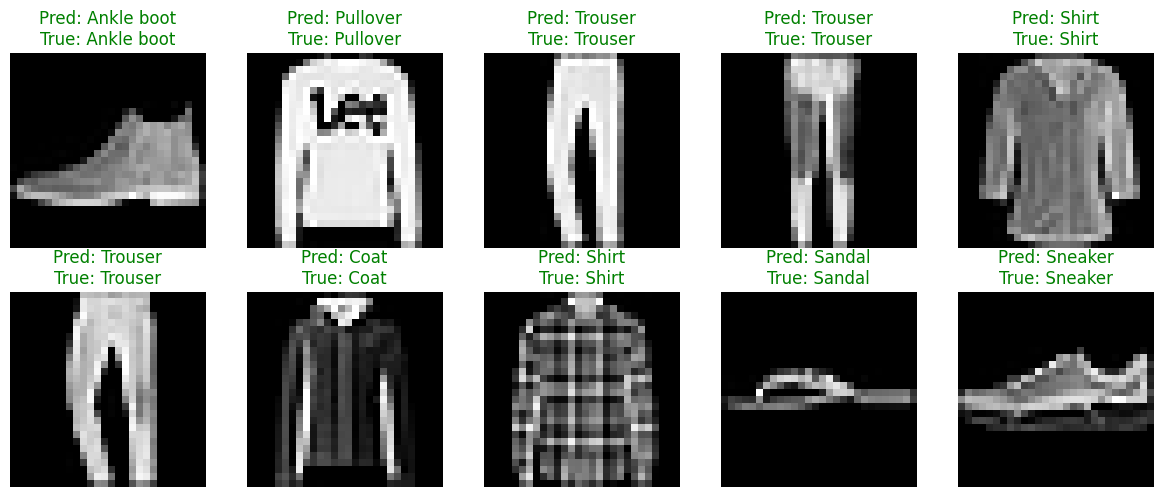

In [9]:
model.eval()
images,labels=next(iter(test_loader))
with torch.no_grad(): predictions=model(images.to(device)).argmax(1).cpu()
fig,axes=plt.subplots(2,5,figsize=(12,5))
for i,ax in enumerate(axes.flat):
    ax.imshow(images[i].squeeze().numpy()*0.5+0.5,cmap="gray")
    ax.set_title(f"Pred: {class_names[predictions[i]]}\nTrue: {class_names[labels[i]]}",
                 color="green" if predictions[i]==labels[i] else "red")
    ax.axis("off")
plt.tight_layout(); plt.show()

## 10. Conclusion and submission checklist
This notebook creates dataset objects, displays the first three validation images with `show_data`, trains a CNN, and plots cost and validation accuracy.

- [ ] Screenshot the `show_data` output.
- [ ] Screenshot the cost and accuracy plots.
- [ ] Confirm the measured validation accuracy is at least 85%.
- [ ] Save and submit the fully executed notebook.

If accuracy is below 85%, do not claim the target was achieved. Enable a GPU in Colab (Runtime → Change runtime type → T4 GPU), increase `EPOCHS`, and run all cells again.